#  Wavelet-Based Denoising of Time-Series Signals

## 1.3 Real-World Data Analysis: Accelerometer Signals
### 1.3.1 Data Loading and Exploration

Loading Human Posture Recognition Dataset...
Sampling rate: 5.0 Hz
Sensor: Invensense MPU-6050 MEMS IMU



Downloading...
From: https://drive.google.com/uc?id=1GtNRi9CgHOlGpsa-Dlp6uzAqXUVdEh54
To: d:\project-workspace\jupyter-books\wavelet-book\script\data\posture_recognition_data.csv
100%|██████████| 3.20M/3.20M [00:00<00:00, 24.0MB/s]


Dataset shape: (2000, 3)
Time range: 0.00 to 399.80 seconds
Duration: 399.8 seconds



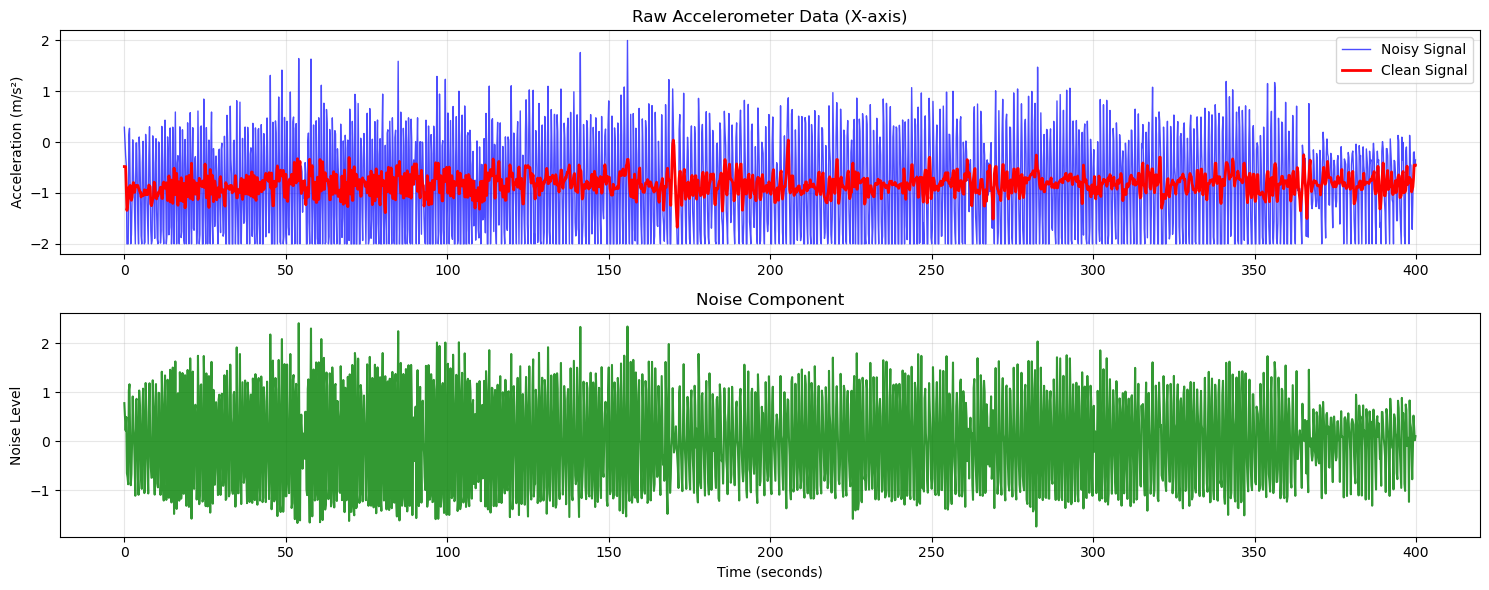

SNR: -13.57 dB
Noise variance: 0.9064


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt
from sklearn.metrics import mean_squared_error
from scipy.signal import savgol_filter
import warnings

warnings.filterwarnings('ignore')

# -------------------------
# Configurations
# -------------------------
DATA_URL = "https://drive.google.com/uc?id=1GtNRi9CgHOlGpsa-Dlp6uzAqXUVdEh54"
SAMPLING_INTERVAL = 0.2  # seconds (200 ms)
FALLBACK_SAMPLES = 1500
RANDOM_SEED = 42


# -------------------------
# Data Loading
# -------------------------
def load_accelerometer_data():
    """
    Loads running activity accelerometer data.
    Attempts to fetch from remote dataset; falls back to synthetic generation.
    
    Returns:
        pd.DataFrame: columns ['timestamp', 'accel_x', 'accel_clean']
    """
    import gdown

    try:
        gdown.download(DATA_URL, "./data/posture_recognition_data.csv", quiet=False, use_cookies=False)
        df_full = pd.read_csv("./data/posture_recognition_data.csv")
        running_data = df_full[df_full['label'] == 3].copy()  # running label = 3

        if len(running_data) > 2000:
            running_data = running_data.head(2000)

        timestamps = np.arange(len(running_data)) * SAMPLING_INTERVAL
        accel_raw = running_data['Ax1'].values

        # Moving average smoothing
        accel_clean = (
            pd.Series(accel_raw)
            .rolling(window=5, center=True)
            .mean()
            .bfill()
            .ffill()
            .values
        )

        return pd.DataFrame({
            'timestamp': timestamps,
            'accel_x': accel_raw,
            'accel_clean': accel_clean
        })

    except Exception as e:
        print(f"⚠️ Could not load dataset: {e}")
        print("Generating synthetic running-like accelerometer data...")

        np.random.seed(RANDOM_SEED)
        t = np.arange(FALLBACK_SAMPLES) * SAMPLING_INTERVAL

        # Simulate base running pattern
        base_freq = 2.5  # Hz
        signal = (
            4.0 * np.sin(2 * np.pi * base_freq * t) +
            0.6 * np.sin(2 * np.pi * 2 * base_freq * t) +
            0.3 * np.sin(2 * np.pi * 4 * base_freq * t)
        )

        # Add noise components
        measurement_noise = 0.05 * np.random.randn(FALLBACK_SAMPLES)
        vibration_noise = 0.03 * np.random.randn(FALLBACK_SAMPLES)
        high_freq = 0.02 * np.sin(2 * np.pi * 20 * t) * np.random.randn(FALLBACK_SAMPLES)

        spikes = np.zeros(FALLBACK_SAMPLES)
        spike_indices = np.random.choice(FALLBACK_SAMPLES, size=FALLBACK_SAMPLES // 50, replace=False)
        spikes[spike_indices] = np.random.randn(len(spike_indices)) * 0.2

        noisy_signal = signal + measurement_noise + vibration_noise + high_freq + spikes

        # "Clean" version using Savitzky-Golay smoothing
        clean_signal = savgol_filter(noisy_signal, window_length=11, polyorder=3)

        return pd.DataFrame({
            'timestamp': t,
            'accel_x': noisy_signal,
            'accel_clean': clean_signal
        })


# -------------------------
# Visualization
# -------------------------
def plot_accelerometer_data(df):
    plt.figure(figsize=(15, 6))

    plt.subplot(2, 1, 1)
    plt.plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.7, lw=1, label='Noisy Signal')
    plt.plot(df['timestamp'], df['accel_clean'], 'r-', lw=2, label='Clean Signal')
    plt.title('Raw Accelerometer Data (X-axis)')
    plt.ylabel('Acceleration (m/s²)')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 1, 2)
    noise = df['accel_x'] - df['accel_clean']
    plt.plot(df['timestamp'], noise, 'g-', alpha=0.8)
    plt.title('Noise Component')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Noise Level')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('./output/accelerometer_data_plot.png', dpi=300)
    plt.show()


# -------------------------
# Statistics
# -------------------------
def compute_signal_statistics(df):
    """Prints SNR and noise variance."""
    noise = df['accel_x'] - df['accel_clean']
    snr = 10 * np.log10(np.var(df['accel_clean']) / np.var(noise))
    print(f"SNR: {snr:.2f} dB")
    print(f"Noise variance: {np.var(noise):.4f}")


# -------------------------
# Main Execution
# -------------------------
if __name__ == "__main__":
    print("Loading Human Posture Recognition Dataset...")
    print("Sampling rate: {:.1f} Hz".format(1 / SAMPLING_INTERVAL))
    print("Sensor: Invensense MPU-6050 MEMS IMU\n")

    df = load_accelerometer_data()
    print(f"Dataset shape: {df.shape}")
    print(f"Time range: {df['timestamp'].min():.2f} to {df['timestamp'].max():.2f} seconds")
    print(f"Duration: {df['timestamp'].max() - df['timestamp'].min():.1f} seconds\n")

    plot_accelerometer_data(df)
    compute_signal_statistics(df)


### 1.2 Wavelet Analysis of the Signal

Downloading...
From: https://drive.google.com/uc?id=1GtNRi9CgHOlGpsa-Dlp6uzAqXUVdEh54
To: d:\project-workspace\jupyter-books\wavelet-book\script\data\posture_recognition_data.csv
100%|██████████| 3.20M/3.20M [00:00<00:00, 22.1MB/s]


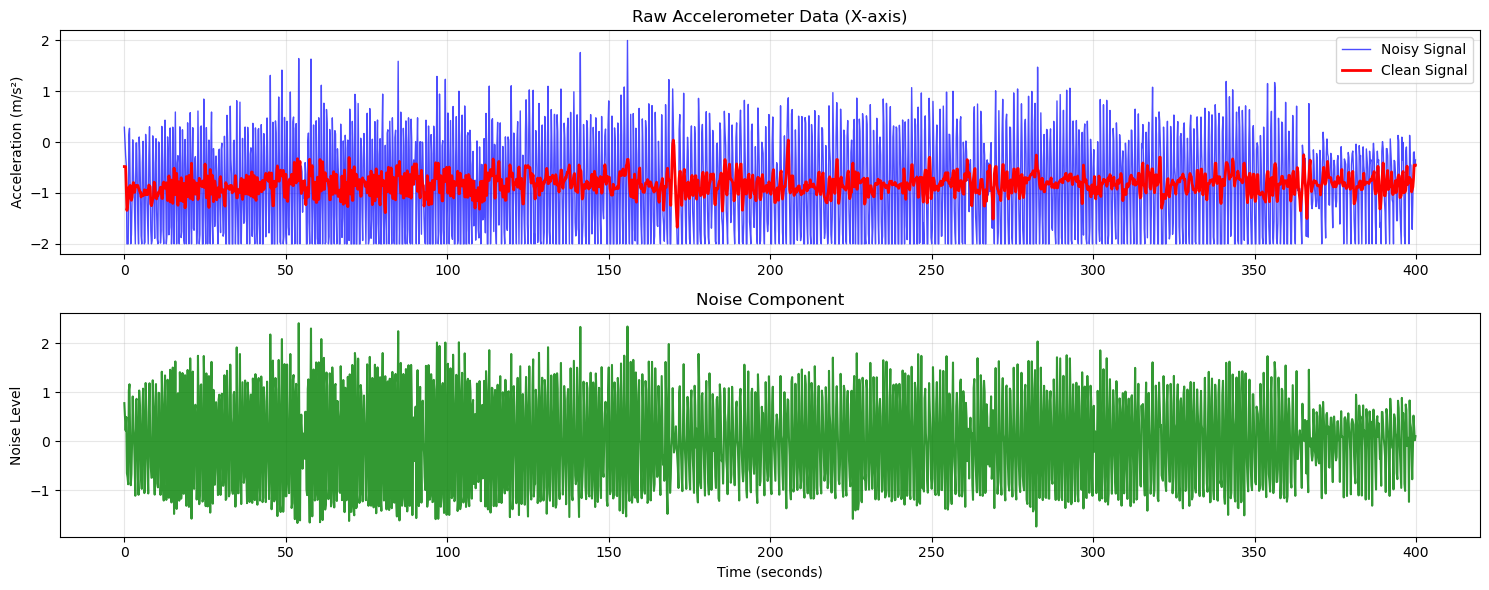


Wavelet Decomposition Analysis (db6, 5 levels, signal length: 2000):
Level      Coefficients    Energy %     Max Coeff   
-------------------------------------------------------
Approx     73              45.27        5.4691      
Detail 1   73              0.27         1.0040      
Detail 2   135             0.51         1.7472      
Detail 3   259             2.14         2.6519      
Detail 4   508             38.13        3.1377      
Detail 5   1005            13.68        1.9619      


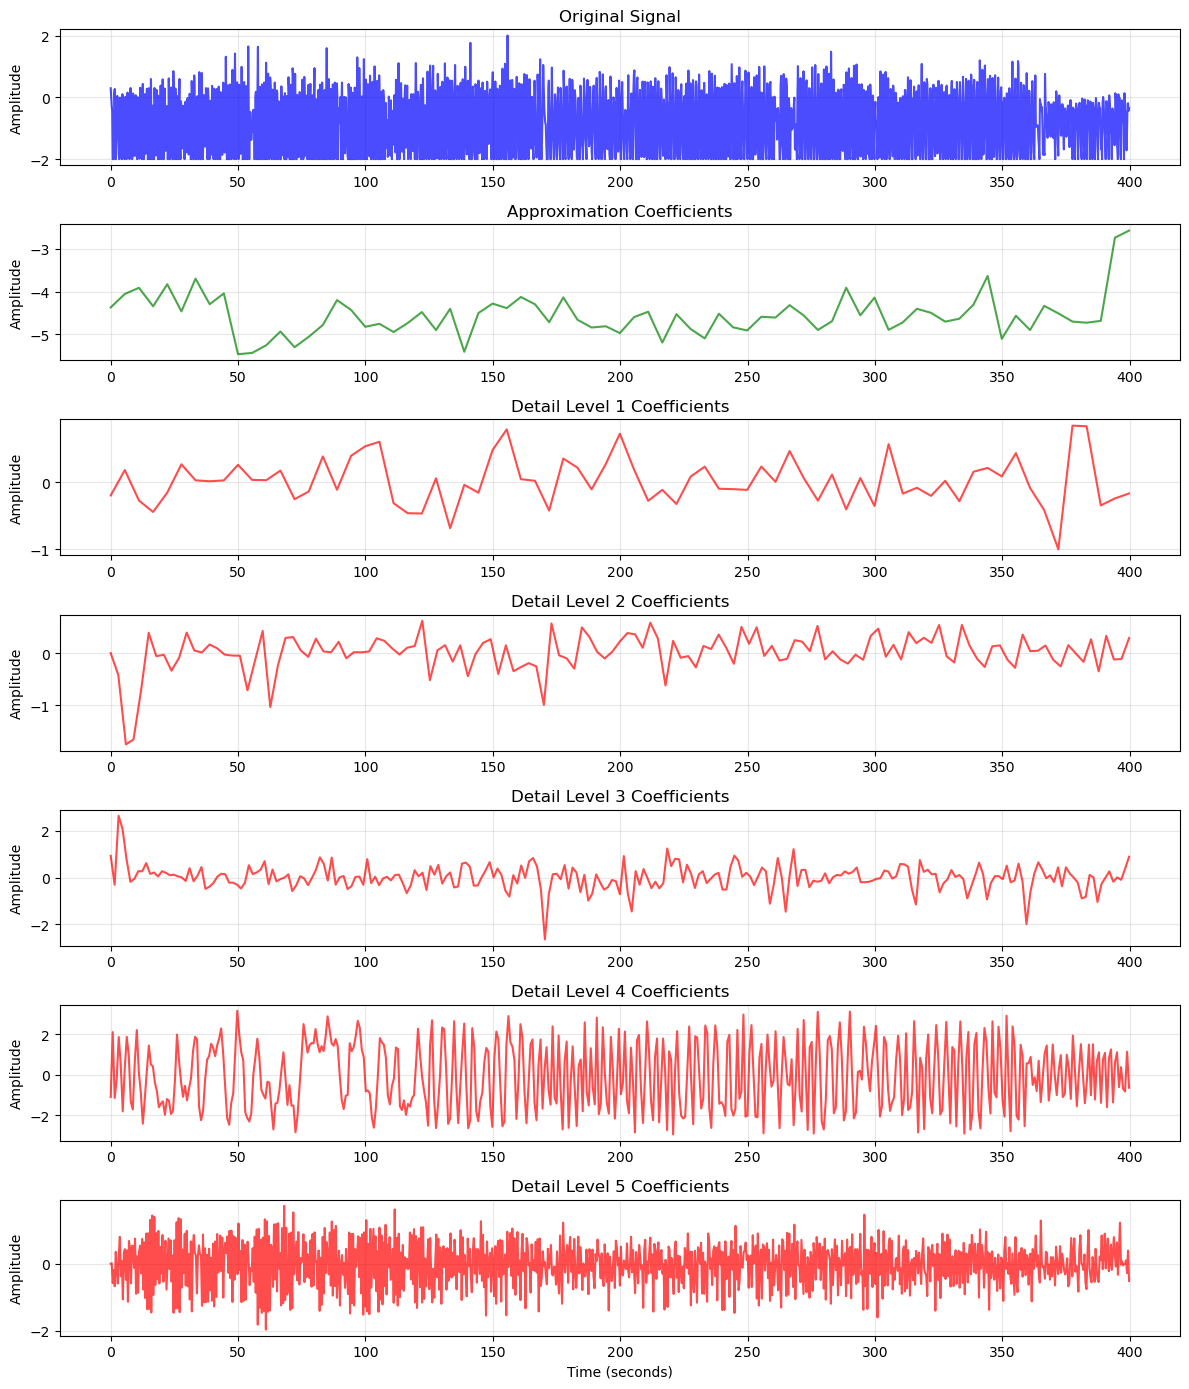

In [ ]:
def analyze_wavelet_decomposition(signal, wavelet='db6', levels=5):
    """
    Analyze wavelet decomposition of a signal, computing energy ratios and visualizing coefficients.
    
    Args:
        signal (np.ndarray): Input signal to decompose
        wavelet (str): Wavelet type (e.g., 'db6')
        levels (int): Number of decomposition levels
    
    Returns:
        tuple: (coefficients, energy_ratios)
    """
    # Validate input signal
    if not isinstance(signal, np.ndarray) or len(signal) < 2:
        raise ValueError("Input signal must be a non-empty numpy array")
    
    # Calculate maximum decomposition levels
    max_levels = pywt.dwt_max_level(len(signal), wavelet)
    levels = min(levels, max_levels)
    if levels < 1:
        raise ValueError(f"Signal too short for decomposition with {wavelet}. Max levels: {max_levels}")

    # Perform wavelet decomposition
    coeffs = pywt.wavedec(signal, wavelet, level=levels)
    
    # Calculate energy at each level
    energies = [np.sum(c**2) for c in coeffs]
    total_energy = sum(energies)
    
    # Avoid division by zero
    if total_energy == 0:
        raise ValueError("Total energy is zero, cannot compute energy ratios")
    
    energy_ratios = [e / total_energy for e in energies]
    
    # Print analysis
    print(f"\nWavelet Decomposition Analysis ({wavelet}, {levels} levels, signal length: {len(signal)}):")
    print(f"{'Level':<10} {'Coefficients':<15} {'Energy %':<12} {'Max Coeff':<12}")
    print("-" * 55)
    
    for i, (coeff, energy_pct) in enumerate(zip(coeffs, energy_ratios)):
        level_name = "Approx" if i == 0 else f"Detail {i}"
        print(f"{level_name:<10} {len(coeff):<15} {energy_pct*100:<12.2f} {np.max(np.abs(coeff)):<12.4f}")
    
    # Visualize decomposition
    fig, axes = plt.subplots(levels + 2, 1, figsize=(12, 2 * (levels + 2)))
    
    # Ensure axes is iterable for low levels
    if not isinstance(axes, np.ndarray):
        axes = np.array([axes])
    
    # Plot original signal
    time = np.arange(len(signal)) * SAMPLING_INTERVAL
    axes[0].plot(time, signal, 'b-', alpha=0.7)
    axes[0].set_title("Original Signal")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(True, alpha=0.3)
    
    # Plot approximation coefficients
    coeff_time = np.linspace(0, time[-1], len(coeffs[0]))
    axes[1].plot(coeff_time, coeffs[0], 'g-', alpha=0.7)
    axes[1].set_title("Approximation Coefficients")
    axes[1].set_ylabel("Amplitude")
    axes[1].grid(True, alpha=0.3)
    
    # Plot detail coefficients
    for i, coeff in enumerate(coeffs[1:], 1):
        level_name = f"Detail Level {i}"
        coeff_time = np.linspace(0, time[-1], len(coeff))
        axes[i + 1].plot(coeff_time, coeff, 'r-', alpha=0.7)
        axes[i + 1].set_title(f"{level_name} Coefficients")
        axes[i + 1].set_ylabel("Amplitude")
        axes[i + 1].grid(True, alpha=0.3)
    
    axes[-1].set_xlabel("Time (seconds)")
    plt.tight_layout()
    plt.savefig("./output/posture_recognition_data_wavelet_decomposition.png", dpi=300)
    plt.show()
    plt.close()
    
    return coeffs, energy_ratios

# -------------------------
# Main Execution
# -------------------------
if __name__ == "__main__":
    df = load_accelerometer_data()
    plot_accelerometer_data(df)
 
    # Analyze wavelet decomposition
    signal = df['accel_x'].values
    coeffs, energy_ratios = analyze_wavelet_decomposition(signal, wavelet='db6', levels=5)

## 1.4 Denoising Method 1: Detail Coefficient Removal

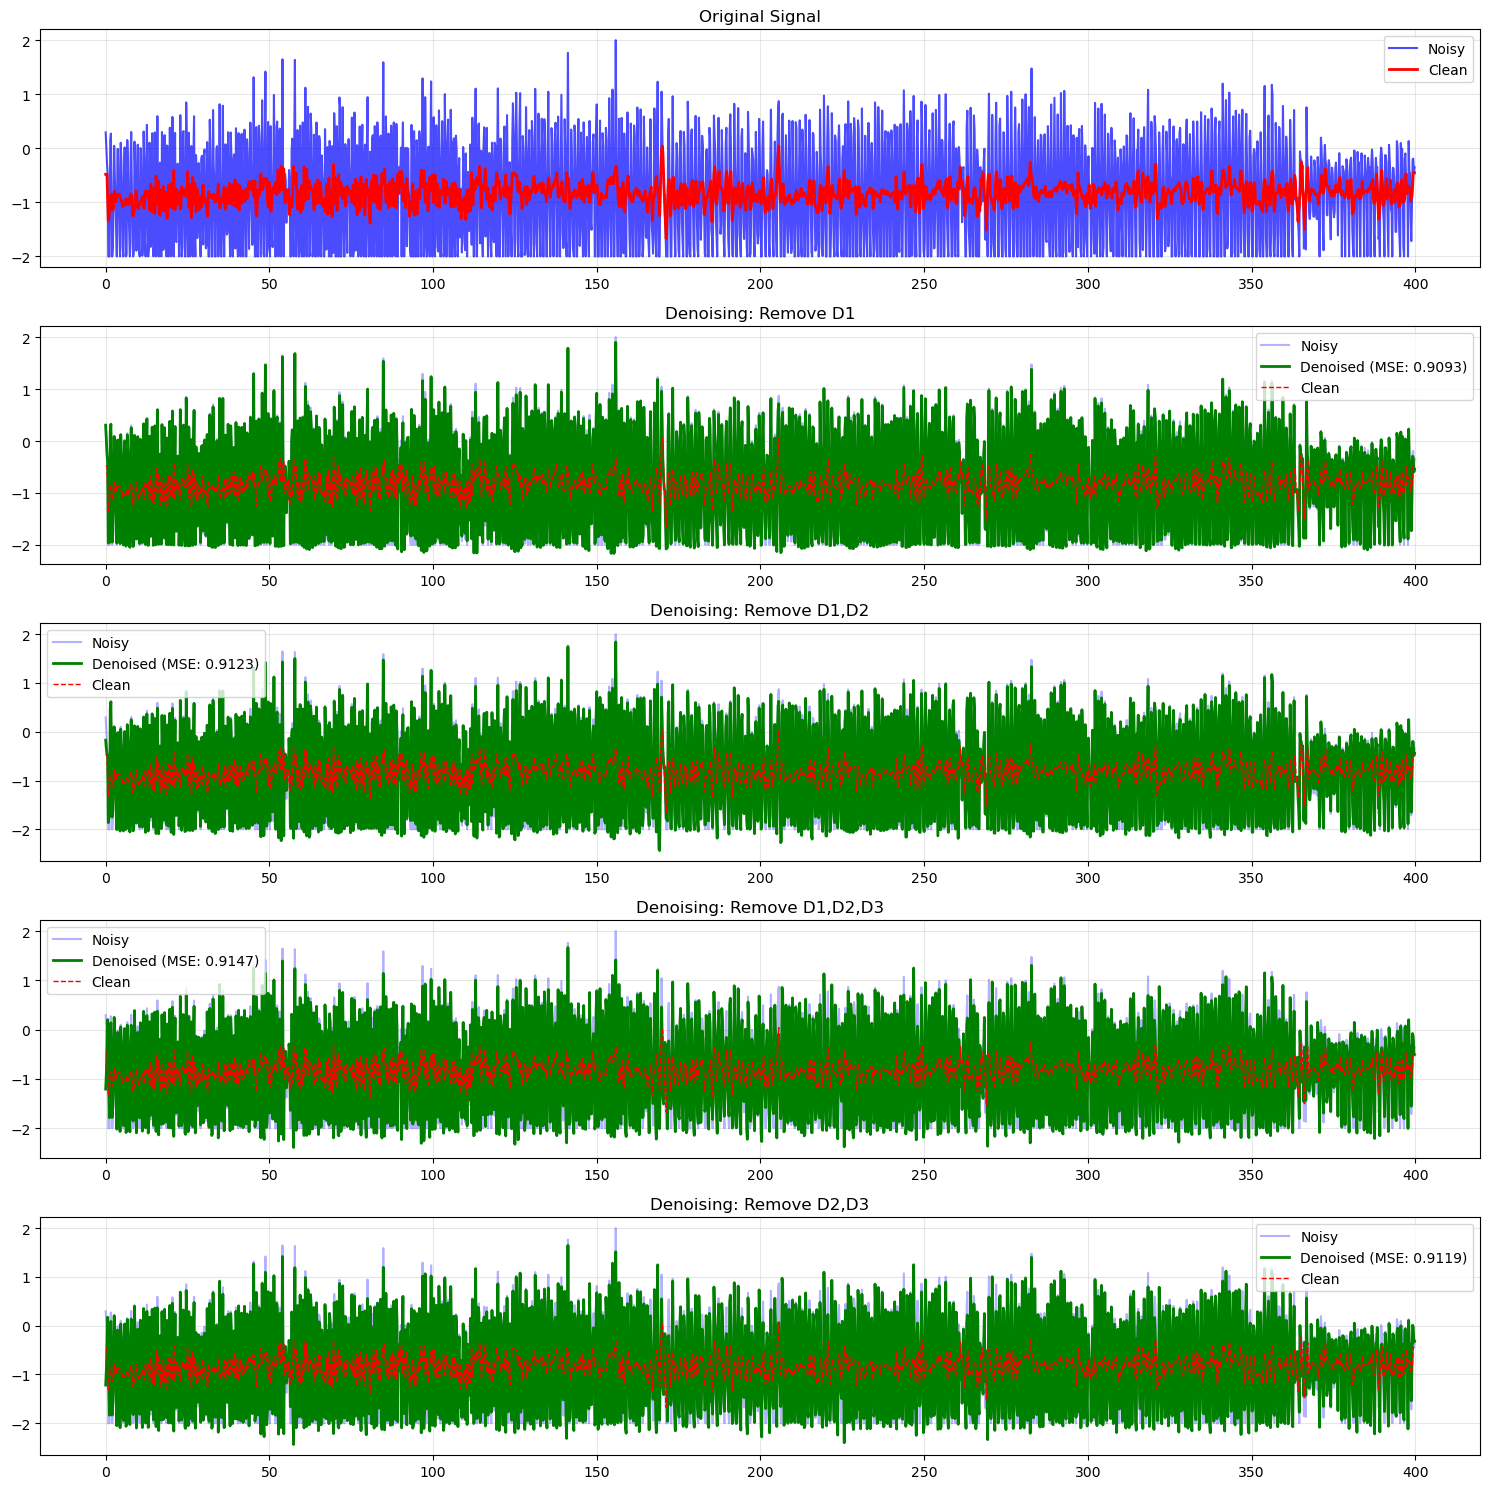

In [ ]:
def denoise_by_coefficient_removal(signal, wavelet='db6', levels_to_remove=[]):
    """
    Denoise by removing specific detail coefficient levels
    
    Parameters:
    - signal: input noisy signal
    - wavelet: wavelet type
    - levels_to_remove: list of detail levels to remove (e.g., [1, 2])
    """
    # Decompose
    coeffs = pywt.wavedec(signal, wavelet, level=max(5, max(levels_to_remove) if levels_to_remove else 3))
    
    # Remove specified detail levels
    coeffs_modified = coeffs.copy()
    for level in levels_to_remove:
        if level < len(coeffs):
            coeffs_modified[level] = np.zeros_like(coeffs[level])
    
    # Reconstruct
    denoised = pywt.waverec(coeffs_modified, wavelet)
    
    # Trim to original length if necessary
    if len(denoised) > len(signal):
        denoised = denoised[:len(signal)]
    
    return denoised

# Test different removal strategies
removal_strategies = {
    'Remove D1': [1],
    'Remove D1,D2': [1, 2],
    'Remove D1,D2,D3': [1, 2, 3],
    'Remove D2,D3': [2, 3]
}

fig, axes = plt.subplots(len(removal_strategies) + 1, 1, figsize=(15, 3*(len(removal_strategies)+1)))

# Original signal
axes[0].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.7, label='Noisy')
axes[0].plot(df['timestamp'], df['accel_clean'], 'r-', linewidth=2, label='Clean')
axes[0].set_title('Original Signal')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Apply different removal strategies
results_removal = {}
for idx, (strategy_name, levels) in enumerate(removal_strategies.items(), 1):
    denoised = denoise_by_coefficient_removal(signal, levels_to_remove=levels)
    results_removal[strategy_name] = denoised
    
    mse = mean_squared_error(df['accel_clean'], denoised[:len(df['accel_clean'])])
    
    axes[idx].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.3, label='Noisy')
    axes[idx].plot(df['timestamp'], denoised[:len(df)], 'g-', linewidth=2, label=f'Denoised (MSE: {mse:.4f})')
    axes[idx].plot(df['timestamp'], df['accel_clean'], 'r--', linewidth=1, label='Clean')
    axes[idx].set_title(f'Denoising: {strategy_name}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/denoising_by_coefficient_removal.png", dpi=300)
plt.show()

## 1.5 Denoising Method 2: Soft and Hard Thresholding


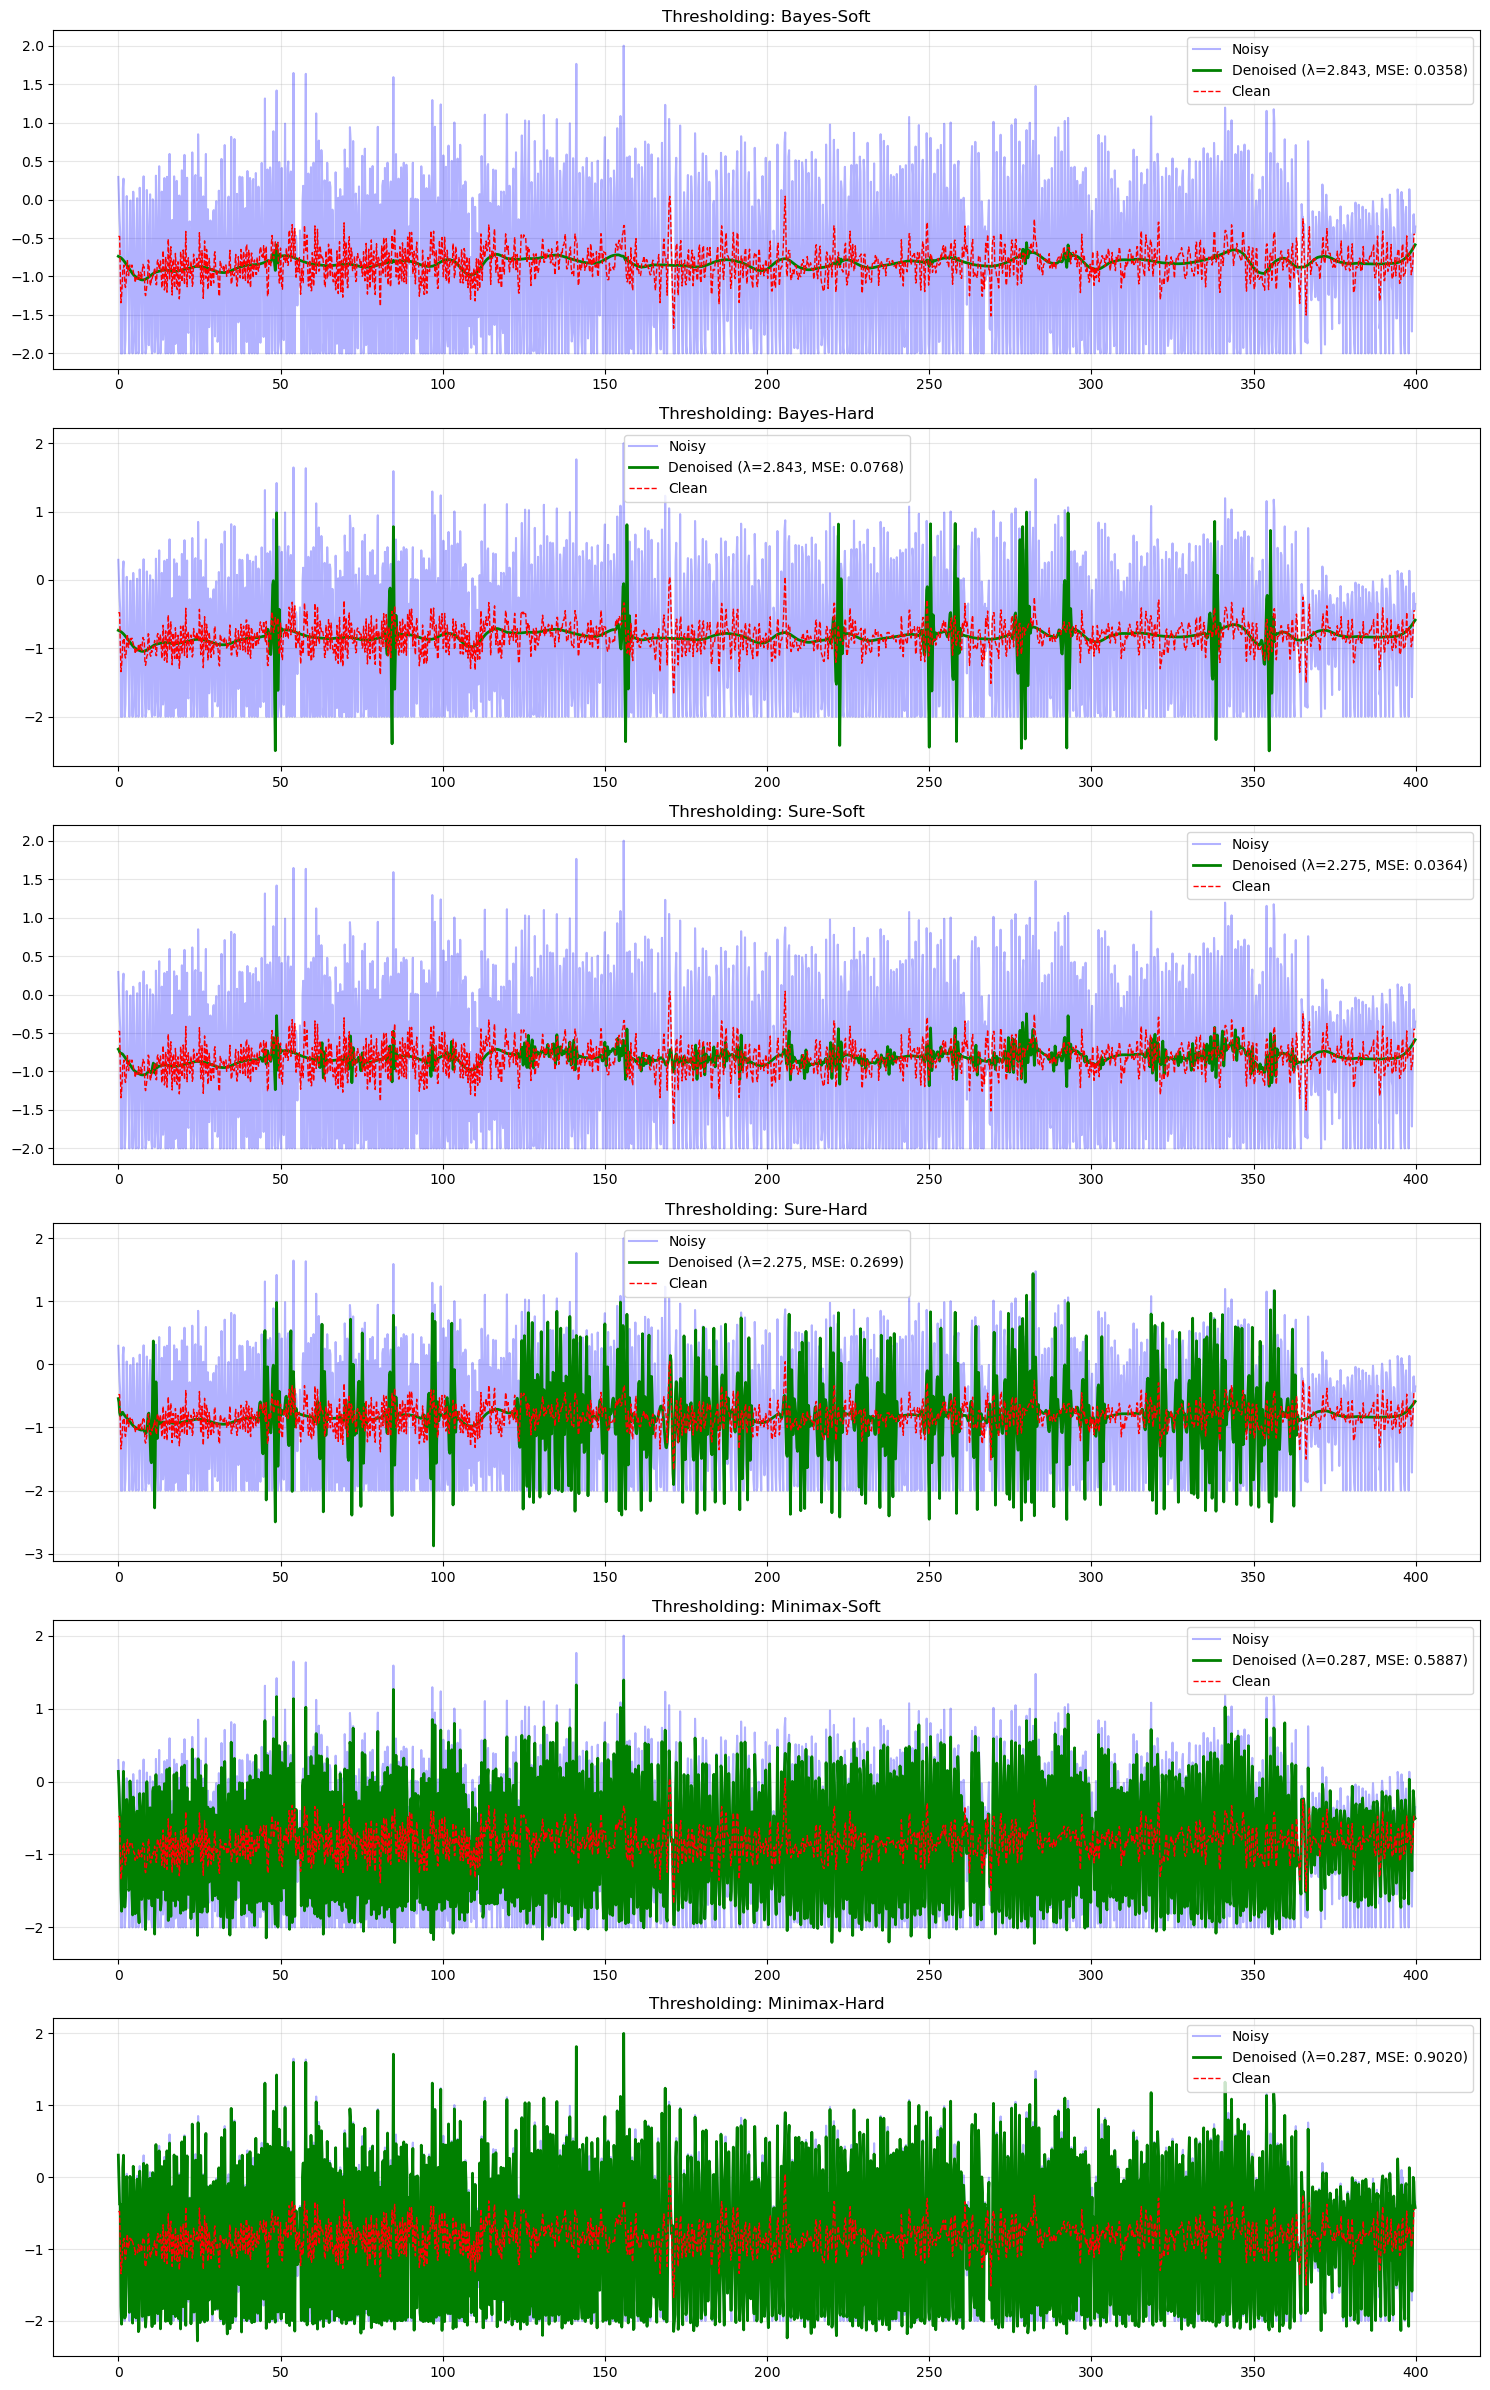

Estimated Threshold Values:
Bayes-Soft     : 2.8433
Bayes-Hard     : 2.8433
Sure-Soft      : 2.2746
Sure-Hard      : 2.2746
Minimax-Soft   : 0.2868
Minimax-Hard   : 0.2868


In [ ]:
def estimate_noise_threshold(signal, wavelet='db6', method='bayes'):
    """
    Estimate optimal threshold for denoising
    
    Methods:
    - 'bayes': BayesShrink method
    - 'sure': Stein's Unbiased Risk Estimator
    - 'minimax': Minimax estimation
    """
    coeffs = pywt.wavedec(signal, wavelet)
    
    if method == 'bayes':
        # Estimate noise variance from finest detail coefficients
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        threshold = sigma * np.sqrt(2 * np.log(len(signal)))
    elif method == 'sure':
        # Simplified SURE-based threshold
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745
        threshold = sigma * np.sqrt(2 * np.log(len(signal))) * 0.8
    else:  # minimax
        threshold = np.std(signal) * 0.3
    
    return threshold

def wavelet_threshold_denoise(signal, wavelet='db6', threshold=None, mode='soft'):
    """
    Denoise using wavelet thresholding
    
    Parameters:
    - signal: input signal
    - wavelet: wavelet type
    - threshold: threshold value (auto-estimated if None)
    - mode: 'soft' or 'hard' thresholding
    """
    # Decompose
    coeffs = pywt.wavedec(signal, wavelet, level=5)
    
    # Estimate threshold if not provided
    if threshold is None:
        threshold = estimate_noise_threshold(signal, wavelet)
    
    # Apply thresholding to detail coefficients only
    coeffs_thresh = [coeffs[0]]  # Keep approximation coefficients unchanged
    
    for i in range(1, len(coeffs)):
        coeffs_thresh.append(pywt.threshold(coeffs[i], threshold, mode=mode))
    
    # Reconstruct
    denoised = pywt.waverec(coeffs_thresh, wavelet)
    
    # Trim to original length
    if len(denoised) > len(signal):
        denoised = denoised[:len(signal)]
    
    return denoised, threshold

# Compare different thresholding approaches
threshold_methods = ['bayes', 'sure', 'minimax']
thresholding_modes = ['soft', 'hard']

results_threshold = {}
threshold_values = {}

fig, axes = plt.subplots(len(threshold_methods) * len(thresholding_modes), 1, 
                         figsize=(15, 4*len(threshold_methods)*len(thresholding_modes)))

plot_idx = 0
for method in threshold_methods:
    for mode in thresholding_modes:
        # Auto-estimate threshold
        threshold = estimate_noise_threshold(signal, method=method)
        
        # Apply denoising
        denoised, actual_threshold = wavelet_threshold_denoise(
            signal, threshold=threshold, mode=mode
        )
        
        method_name = f"{method.title()}-{mode.title()}"
        results_threshold[method_name] = denoised
        threshold_values[method_name] = actual_threshold
        
        # Calculate performance metrics
        mse = mean_squared_error(df['accel_clean'], denoised[:len(df['accel_clean'])])
        
        # Plot
        axes[plot_idx].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.3, label='Noisy')
        axes[plot_idx].plot(df['timestamp'], denoised[:len(df)], 'g-', linewidth=2, 
                           label=f'Denoised (λ={actual_threshold:.3f}, MSE: {mse:.4f})')
        axes[plot_idx].plot(df['timestamp'], df['accel_clean'], 'r--', linewidth=1, label='Clean')
        axes[plot_idx].set_title(f'Thresholding: {method_name}')
        axes[plot_idx].legend()
        axes[plot_idx].grid(True, alpha=0.3)
        
        plot_idx += 1

plt.tight_layout()
plt.savefig("./output/denoising_by_thresholding.png", dpi=300)
plt.show()

# Print threshold values for comparison
print("Estimated Threshold Values:")
for method, threshold in threshold_values.items():
    print(f"{method:<15}: {threshold:.4f}")

## 1.6 Adaptive Thresholding and Advanced Techniques

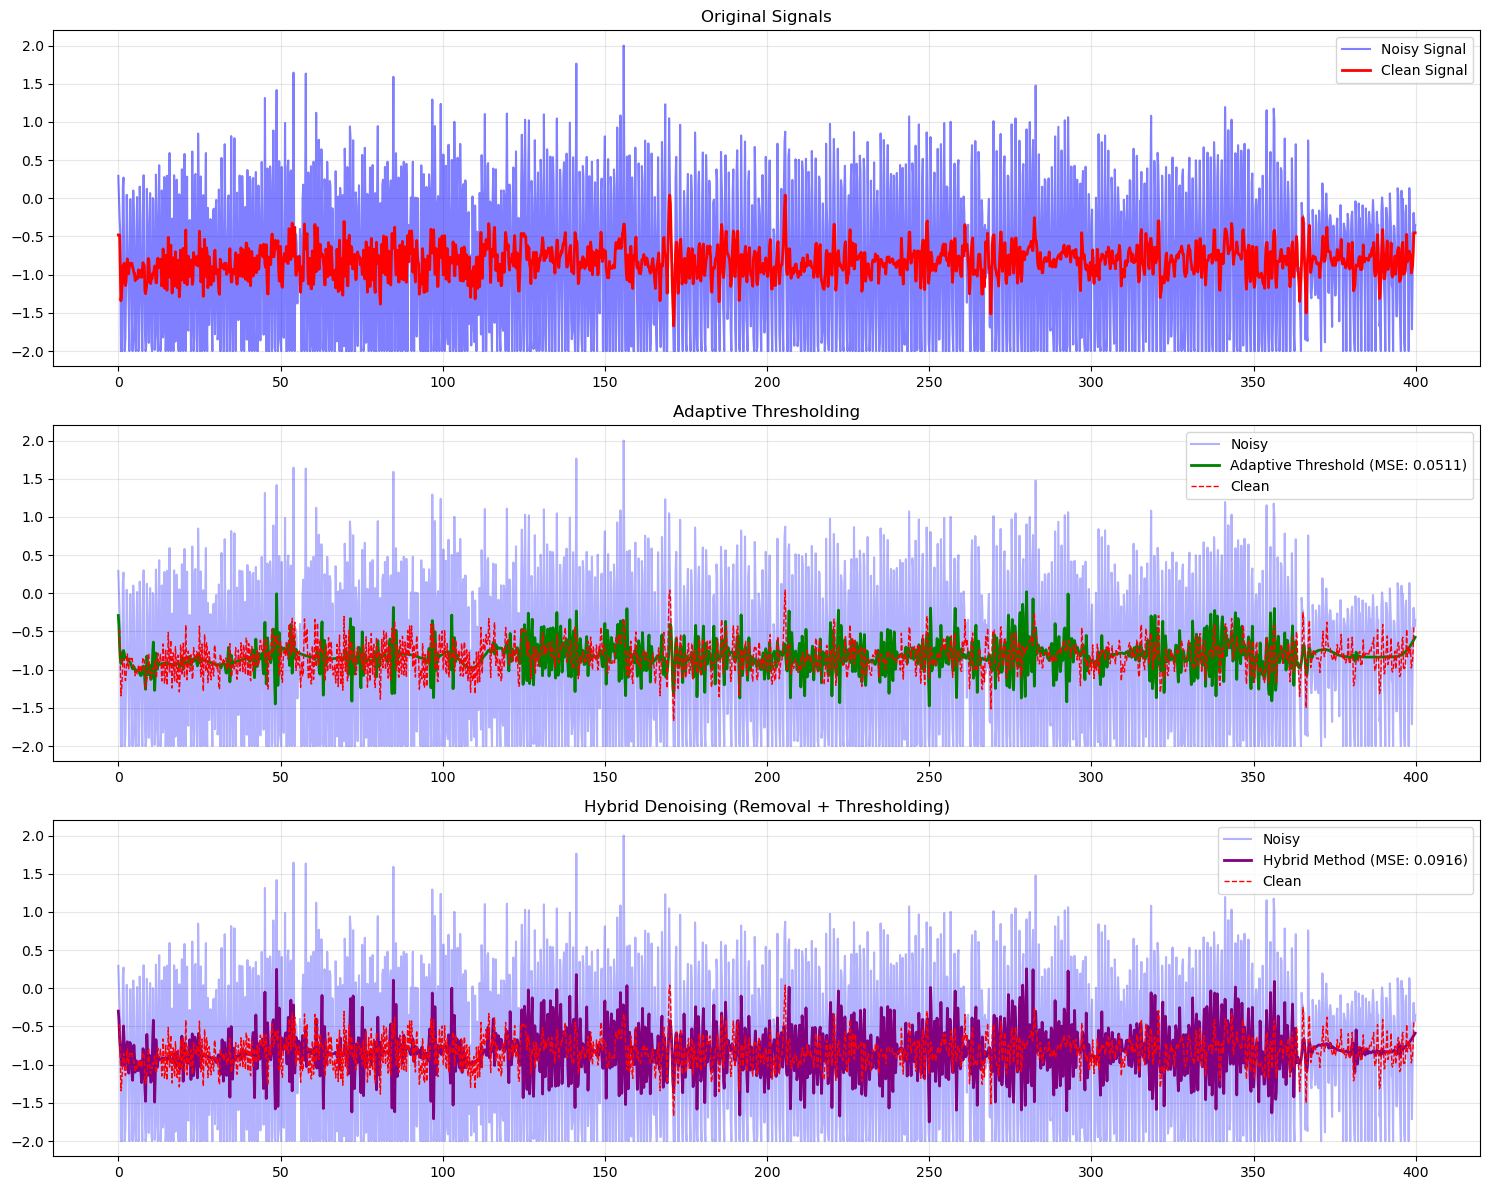

In [ ]:
def adaptive_threshold_denoise(signal, wavelet='db6', base_threshold=None):
    """
    Apply level-dependent thresholding for better preservation of signal features
    """
    coeffs = pywt.wavedec(signal, wavelet, level=5)
    
    if base_threshold is None:
        base_threshold = estimate_noise_threshold(signal, method='bayes')
    
    # Apply different thresholds for different levels
    coeffs_thresh = [coeffs[0]]  # Keep approximation
    
    for i in range(1, len(coeffs)):
        # Reduce threshold for coarser scales (preserve important features)
        level_threshold = base_threshold * (0.8 ** (len(coeffs) - i))
        coeffs_thresh.append(pywt.threshold(coeffs[i], level_threshold, mode='soft'))
    
    denoised = pywt.waverec(coeffs_thresh, wavelet)
    
    if len(denoised) > len(signal):
        denoised = denoised[:len(signal)]
    
    return denoised

def hybrid_denoise(signal, wavelet='db6'):
    """
    Combine coefficient removal and thresholding for optimal results
    """
    # Step 1: Remove highest frequency detail (often pure noise)
    coeffs = pywt.wavedec(signal, wavelet, level=5)
    coeffs[1] = np.zeros_like(coeffs[1])  # Remove D1
    
    # Step 2: Apply soft thresholding to remaining details
    threshold = estimate_noise_threshold(signal, method='bayes') * 0.5
    for i in range(2, len(coeffs)):
        coeffs[i] = pywt.threshold(coeffs[i], threshold, mode='soft')
    
    denoised = pywt.waverec(coeffs, wavelet)
    
    if len(denoised) > len(signal):
        denoised = denoised[:len(signal)]
    
    return denoised

# Apply advanced methods
adaptive_result = adaptive_threshold_denoise(signal)
hybrid_result = hybrid_denoise(signal)

# Visualize results
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Original comparison
axes[0].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.5, label='Noisy Signal')
axes[0].plot(df['timestamp'], df['accel_clean'], 'r-', linewidth=2, label='Clean Signal')
axes[0].set_title('Original Signals')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Adaptive thresholding
mse_adaptive = mean_squared_error(df['accel_clean'], adaptive_result[:len(df['accel_clean'])])
axes[1].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.3, label='Noisy')
axes[1].plot(df['timestamp'], adaptive_result[:len(df)], 'g-', linewidth=2, 
             label=f'Adaptive Threshold (MSE: {mse_adaptive:.4f})')
axes[1].plot(df['timestamp'], df['accel_clean'], 'r--', linewidth=1, label='Clean')
axes[1].set_title('Adaptive Thresholding')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Hybrid approach
mse_hybrid = mean_squared_error(df['accel_clean'], hybrid_result[:len(df['accel_clean'])])
axes[2].plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.3, label='Noisy')
axes[2].plot(df['timestamp'], hybrid_result[:len(df)], 'purple', linewidth=2, 
             label=f'Hybrid Method (MSE: {mse_hybrid:.4f})')
axes[2].plot(df['timestamp'], df['accel_clean'], 'r--', linewidth=1, label='Clean')
axes[2].set_title('Hybrid Denoising (Removal + Thresholding)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/advanced_denoising_methods.png", dpi=300)
plt.show()

## 1.7 Performance Evaluation and Comparison

Performance Comparison of Denoising Methods:
                 MSE  SNR_improvement_dB  Correlation    PRMS_%
Remove D1     0.9093             -0.0137       0.1091  477.5866
Remove D1,D2  0.9123             -0.0283       0.0857  478.3873
Bayes-Soft    0.0358             14.0307       0.3184   94.8072
Sure-Soft     0.0364             13.9584       0.3347   95.5996
Bayes-Hard    0.0768             10.7218       0.1690  138.7655
Adaptive      0.0511             12.4911       0.2953  113.1934
Hybrid        0.0916              9.9563       0.2361  151.5502


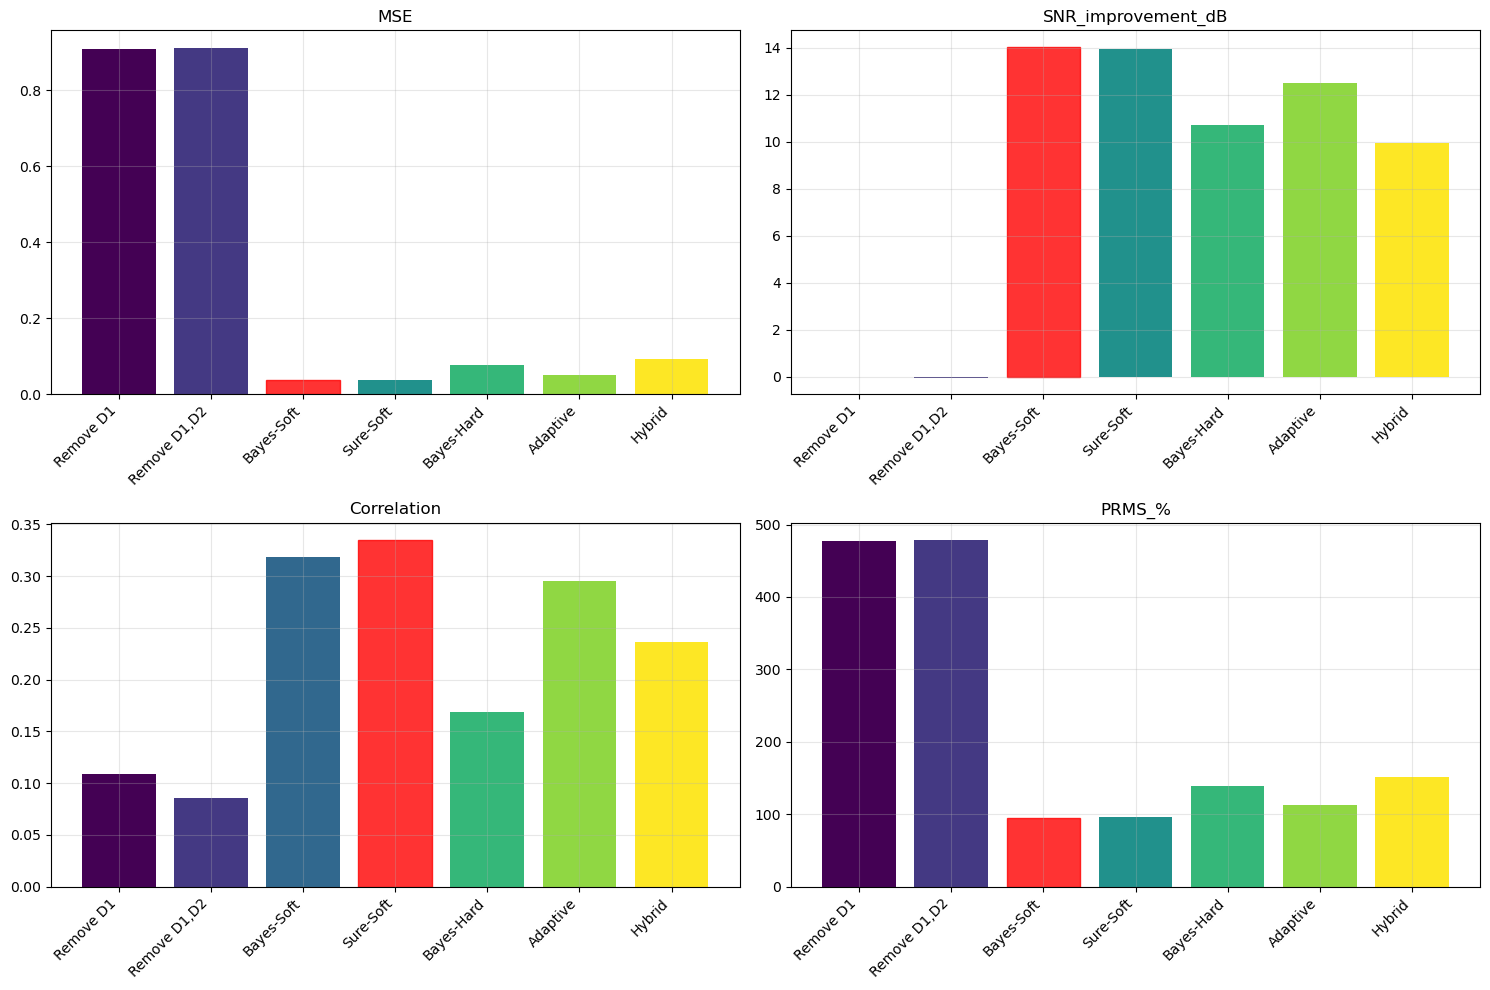


Best Method for Each Metric:
----------------------------------------
MSE                 : Bayes-Soft (0.0358)
SNR_improvement_dB  : Bayes-Soft (14.0307)
Correlation         : Sure-Soft (0.3347)
PRMS_%              : Bayes-Soft (94.8072)


In [ ]:
def calculate_metrics(clean_signal, denoised_signal):
    """
    Calculate comprehensive performance metrics
    """
    # Ensure same length
    min_len = min(len(clean_signal), len(denoised_signal))
    clean = clean_signal[:min_len]
    denoised = denoised_signal[:min_len]
    
    # Mean Squared Error
    mse = mean_squared_error(clean, denoised)
    
    # Signal-to-Noise Ratio improvement
    noise_original = signal[:min_len] - clean
    noise_denoised = denoised - clean
    
    snr_original = 10 * np.log10(np.var(clean) / np.var(noise_original))
    snr_denoised = 10 * np.log10(np.var(clean) / np.var(noise_denoised))
    snr_improvement = snr_denoised - snr_original
    
    # Correlation coefficient
    correlation = np.corrcoef(clean, denoised)[0, 1]
    
    # Percent Root Mean Square Difference
    prms = 100 * np.sqrt(mse) / np.std(clean)
    
    return {
        'MSE': mse,
        'SNR_improvement_dB': snr_improvement,
        'Correlation': correlation,
        'PRMS_%': prms
    }

# Collect all results for comparison
all_methods = {
    'Remove D1': results_removal['Remove D1'],
    'Remove D1,D2': results_removal['Remove D1,D2'],
    'Bayes-Soft': results_threshold['Bayes-Soft'],
    'Sure-Soft': results_threshold['Sure-Soft'],
    'Bayes-Hard': results_threshold['Bayes-Hard'],
    'Adaptive': adaptive_result,
    'Hybrid': hybrid_result
}

# Evaluate all methods
results_comparison = {}
for method_name, denoised_signal in all_methods.items():
    metrics = calculate_metrics(df['accel_clean'], denoised_signal)
    results_comparison[method_name] = metrics

# Create comparison table
comparison_df = pd.DataFrame(results_comparison).T
comparison_df = comparison_df.round(4)

print("Performance Comparison of Denoising Methods:")
print("=" * 70)
print(comparison_df)

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = ['MSE', 'SNR_improvement_dB', 'Correlation', 'PRMS_%']
for i, metric in enumerate(metrics):
    ax = axes[i//2, i%2]
    values = comparison_df[metric].values
    methods = comparison_df.index
    
    colors = plt.cm.viridis(np.linspace(0, 1, len(methods)))
    bars = ax.bar(range(len(methods)), values, color=colors)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods, rotation=45, ha='right')
    ax.set_title(f'{metric}')
    ax.grid(True, alpha=0.3)
    
    # Highlight best performance
    if metric in ['SNR_improvement_dB', 'Correlation']:
        best_idx = np.argmax(values)
    else:
        best_idx = np.argmin(values)
    bars[best_idx].set_color('red')
    bars[best_idx].set_alpha(0.8)

plt.tight_layout()
plt.savefig("./output/9.6_denoising_methods_comparison.png", dpi=300)
plt.show()

# Find best method for each metric
print("\nBest Method for Each Metric:")
print("-" * 40)
for metric in metrics:
    if metric in ['SNR_improvement_dB', 'Correlation']:
        best_method = comparison_df[metric].idxmax()
        best_value = comparison_df[metric].max()
    else:
        best_method = comparison_df[metric].idxmin()
        best_value = comparison_df[metric].min()
    
    print(f"{metric:<20}: {best_method} ({best_value:.4f})")

## 1.8 Practical Implementation Function

Estimated noise level: 0.7292
Method details: Base threshold: 2.2746


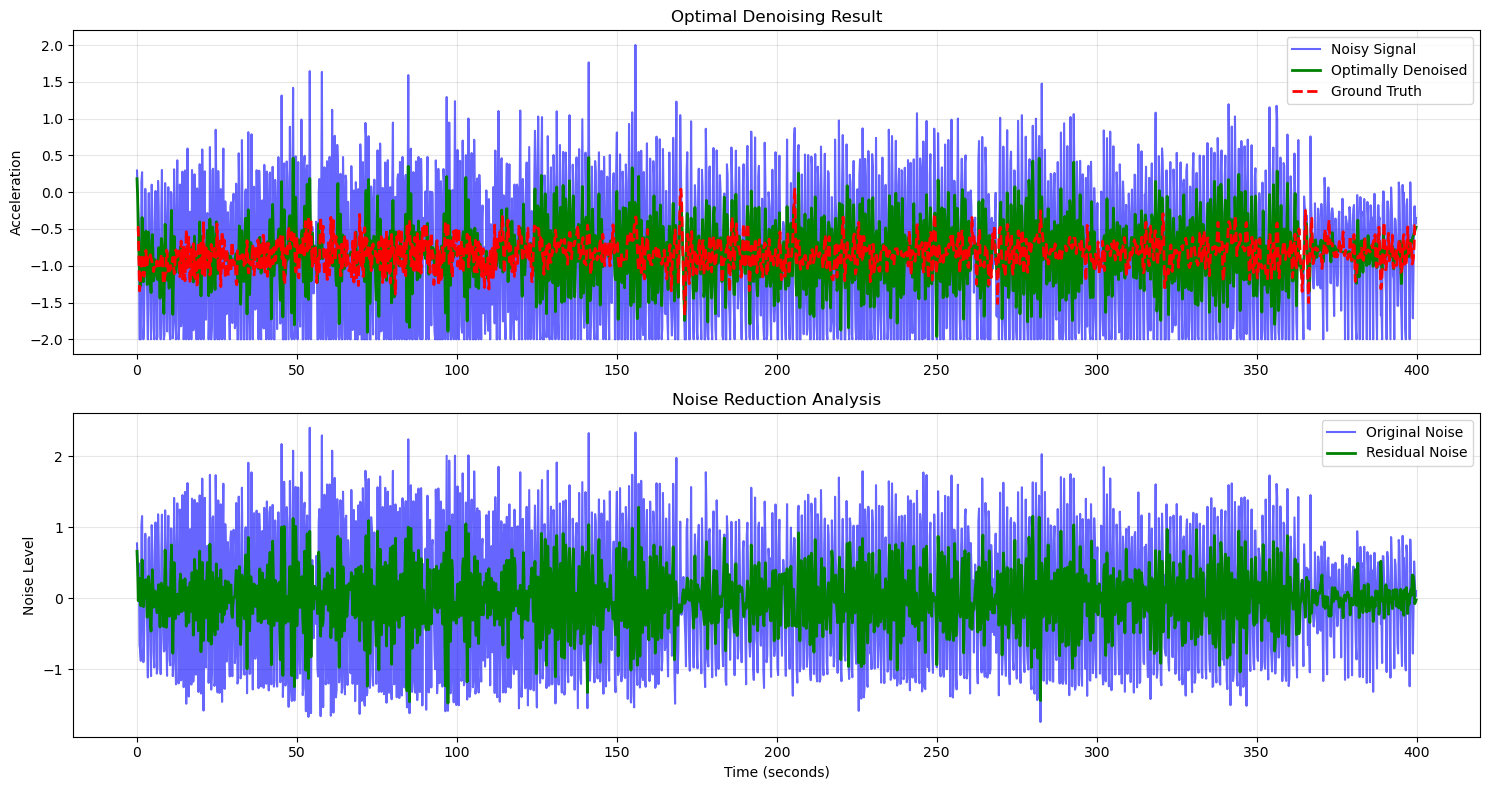


Optimal Method Performance:
MSE: 0.1443
SNR_improvement_dB: 7.9809
Correlation: 0.2504
PRMS_%: 190.2503


In [ ]:
def optimal_wavelet_denoise(data, wavelet='db6', method='adaptive', **kwargs):
    """
    Optimized wavelet denoising function for sensor data
    
    Parameters:
    - data: input time series (1D array or pandas Series)
    - wavelet: wavelet type ('db6' recommended for sensor data)
    - method: 'adaptive', 'hybrid', 'soft_threshold', 'hard_threshold', 'remove_details'
    - **kwargs: additional parameters for specific methods
    
    Returns:
    - denoised signal, estimated noise level, method details
    """
    
    # Convert to numpy array if pandas Series
    if hasattr(data, 'values'):
        signal = data.values
    else:
        signal = np.array(data)
    
    # Estimate noise level
    coeffs = pywt.wavedec(signal, wavelet, level=5)
    noise_estimate = np.median(np.abs(coeffs[-1])) / 0.6745
    
    if method == 'adaptive':
        # Adaptive level-dependent thresholding
        base_threshold = noise_estimate * np.sqrt(2 * np.log(len(signal))) * 0.8
        coeffs_thresh = [coeffs[0]]
        
        for i in range(1, len(coeffs)):
            level_threshold = base_threshold * (0.7 ** (len(coeffs) - i))
            coeffs_thresh.append(pywt.threshold(coeffs[i], level_threshold, mode='soft'))
            
        denoised = pywt.waverec(coeffs_thresh, wavelet)
        details = f"Base threshold: {base_threshold:.4f}"
        
    elif method == 'hybrid':
        # Remove highest frequency + threshold others
        coeffs[1] = np.zeros_like(coeffs[1])  # Remove D1
        threshold = noise_estimate * np.sqrt(2 * np.log(len(signal))) * 0.4
        
        for i in range(2, len(coeffs)):
            coeffs[i] = pywt.threshold(coeffs[i], threshold, mode='soft')
            
        denoised = pywt.waverec(coeffs, wavelet)
        details = f"Threshold: {threshold:.4f}, Removed D1"
        
    elif method == 'soft_threshold':
        threshold = kwargs.get('threshold', noise_estimate * np.sqrt(2 * np.log(len(signal))))
        coeffs_thresh = [coeffs[0]]
        
        for i in range(1, len(coeffs)):
            coeffs_thresh.append(pywt.threshold(coeffs[i], threshold, mode='soft'))
            
        denoised = pywt.waverec(coeffs_thresh, wavelet)
        details = f"Threshold: {threshold:.4f}"
        
    elif method == 'remove_details':
        levels_to_remove = kwargs.get('levels', [1, 2])
        coeffs_modified = coeffs.copy()
        
        for level in levels_to_remove:
            if level < len(coeffs):
                coeffs_modified[level] = np.zeros_like(coeffs[level])
                
        denoised = pywt.waverec(coeffs_modified, wavelet)
        details = f"Removed levels: {levels_to_remove}"
        
    else:
        raise ValueError(f"Unknown method: {method}")
    
    # Trim to original length
    if len(denoised) > len(signal):
        denoised = denoised[:len(signal)]
    
    return denoised, noise_estimate, details

# Example usage
denoised_optimal, noise_level, method_info = optimal_wavelet_denoise(
    df['accel_x'], method='adaptive'
)

print(f"Estimated noise level: {noise_level:.4f}")
print(f"Method details: {method_info}")

# Final comparison plot
plt.figure(figsize=(15, 8))
plt.subplot(2, 1, 1)
plt.plot(df['timestamp'], df['accel_x'], 'b-', alpha=0.6, label='Noisy Signal')
plt.plot(df['timestamp'], denoised_optimal, 'g-', linewidth=2, label='Optimally Denoised')
plt.plot(df['timestamp'], df['accel_clean'], 'r--', linewidth=2, label='Ground Truth')
plt.title('Optimal Denoising Result')
plt.ylabel('Acceleration')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(df['timestamp'], df['accel_x'] - df['accel_clean'], 'b-', alpha=0.6, label='Original Noise')
plt.plot(df['timestamp'], denoised_optimal - df['accel_clean'], 'g-', linewidth=2, label='Residual Noise')
plt.title('Noise Reduction Analysis')
plt.xlabel('Time (seconds)')
plt.ylabel('Noise Level')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/optimal_wavelet_denoising.png", dpi=300)
plt.show()

# Final performance metrics
final_metrics = calculate_metrics(df['accel_clean'], denoised_optimal)
print(f"\nOptimal Method Performance:")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

## 1.10 Best Practices and Guidelines

### 1.10.1 Wavelet Selection

In [15]:
def recommend_wavelet(signal_characteristics):
    """
    Recommend optimal wavelet based on signal characteristics
    """
    recommendations = {
        'smooth_transients': 'db8',     # Biomedical signals, smooth variations
        'sharp_features': 'haar',        # Digital signals, step changes  
        'oscillatory': 'db4',           # General oscillatory signals
        'sensor_data': 'db6',           # IoT sensor data, accelerometers
        'financial': 'coif4',           # Financial time series
        'seismic': 'db10'               # Geophysical data
    }
    
    return recommendations.get(signal_characteristics, 'db6')

# Example wavelet comparison for our accelerometer data
wavelets_to_test = ['haar', 'db4', 'db6', 'db8', 'coif2', 'bior2.2']
wavelet_performance = {}

for wavelet in wavelets_to_test:
    try:
        denoised, _, _ = optimal_wavelet_denoise(df['accel_x'], wavelet=wavelet, method='adaptive')
        metrics = calculate_metrics(df['accel_clean'], denoised)
        wavelet_performance[wavelet] = metrics['SNR_improvement_dB']
    except:
        wavelet_performance[wavelet] = -999  # Mark failed wavelets

print("Wavelet Performance Comparison (SNR Improvement):")
for wavelet, snr in sorted(wavelet_performance.items(), key=lambda x: x[1], reverse=True):
    if snr > -999:
        print(f"{wavelet:<8}: {snr:>8.3f} dB")

Wavelet Performance Comparison (SNR Improvement):
haar    :   11.771 dB
coif2   :    9.252 dB
db6     :    7.981 dB
db4     :    7.894 dB
db8     :    7.349 dB
bior2.2 :    6.887 dB


### 1.10.2 Parameter Selection Guidelines

In [16]:
def parameter_selection_guide():
    """
    Guidelines for selecting denoising parameters
    """
    guidelines = {
        'decomposition_levels': {
            'rule': 'log2(signal_length)',
            'practical_range': '3-8 levels',
            'note': 'More levels for longer signals, fewer for short bursts'
        },
        'threshold_estimation': {
            'bayes_shrink': 'Good for signals with unknown noise variance',
            'sure': 'Optimal for Gaussian noise with known characteristics', 
            'minimax': 'Conservative approach, good for preserving features'
        },
        'thresholding_mode': {
            'soft': 'Smoother results, better for continuous signals',
            'hard': 'Preserves sharp features, can introduce artifacts'
        }
    }
    
    return guidelines

# Demonstrate adaptive parameter selection
def adaptive_parameter_selection(signal, target_snr_improvement=10):
    """
    Automatically select optimal parameters based on signal characteristics
    """
    signal_length = len(signal)
    
    # Determine decomposition levels
    max_levels = int(np.log2(signal_length))
    optimal_levels = min(6, max_levels - 1)
    
    # Estimate signal characteristics
    coeffs = pywt.wavedec(signal, 'db6', level=optimal_levels)
    noise_estimate = np.median(np.abs(coeffs[-1])) / 0.6745
    signal_energy = np.var(signal)
    estimated_snr = 10 * np.log10(signal_energy / (noise_estimate**2))
    
    # Adapt method based on SNR
    if estimated_snr < 5:  # Very noisy
        method = 'hybrid'
        params = {'aggressive': True}
    elif estimated_snr < 15:  # Moderately noisy
        method = 'adaptive' 
        params = {'conservative': False}
    else:  # Lightly noisy
        method = 'soft_threshold'
        params = {'gentle': True}
    
    return {
        'levels': optimal_levels,
        'method': method,
        'estimated_snr': estimated_snr,
        'noise_estimate': noise_estimate,
        'recommended_params': params
    }

# Apply adaptive selection to our data
adaptive_params = adaptive_parameter_selection(signal)
print("Adaptive Parameter Selection Results:")
for key, value in adaptive_params.items():
    print(f"{key}: {value}")

Adaptive Parameter Selection Results:
levels: 6
method: hybrid
estimated_snr: 2.351732153587757
noise_estimate: 0.7292406504060673
recommended_params: {'aggressive': True}


### 1.10.3 Quality Assessment Metrics

In [17]:
def comprehensive_quality_assessment(original, denoised, ground_truth=None):
    """
    Comprehensive quality assessment for denoised signals
    """
    metrics = {}
    
    # Basic metrics
    if ground_truth is not None:
        metrics.update(calculate_metrics(ground_truth, denoised))
    
    # Signal preservation metrics
    # Spectral coherence
    from scipy import signal as scipy_signal
    f_orig, Pxx_orig = scipy_signal.welch(original, nperseg=min(256, len(original)//4))
    f_den, Pxx_den = scipy_signal.welch(denoised, nperseg=min(256, len(denoised)//4))
    
    # Ensure same length for comparison
    min_len = min(len(Pxx_orig), len(Pxx_den))
    spectral_similarity = np.corrcoef(Pxx_orig[:min_len], Pxx_den[:min_len])[0,1]
    
    # Smoothness measure (second derivative)
    smoothness_orig = np.mean(np.abs(np.diff(original, n=2)))
    smoothness_den = np.mean(np.abs(np.diff(denoised, n=2)))
    smoothness_improvement = (smoothness_orig - smoothness_den) / smoothness_orig
    
    # Peak preservation (for signals with distinct peaks)
    from scipy.signal import find_peaks
    peaks_orig, _ = find_peaks(np.abs(original), height=np.std(original))
    peaks_den, _ = find_peaks(np.abs(denoised), height=np.std(denoised))
    peak_preservation = len(peaks_den) / max(len(peaks_orig), 1)
    
    metrics.update({
        'spectral_similarity': spectral_similarity,
        'smoothness_improvement': smoothness_improvement,
        'peak_preservation_ratio': peak_preservation
    })
    
    return metrics

# Assess our optimal denoising result
quality_metrics = comprehensive_quality_assessment(
    df['accel_x'], denoised_optimal, df['accel_clean']
)

print("Comprehensive Quality Assessment:")
print("=" * 50)
for metric, value in quality_metrics.items():
    print(f"{metric:<25}: {value:>10.4f}")

Comprehensive Quality Assessment:
MSE                      :     0.1443
SNR_improvement_dB       :     7.9809
Correlation              :     0.2504
PRMS_%                   :   190.2503
spectral_similarity      :     0.9491
smoothness_improvement   :     0.7329
peak_preservation_ratio  :     0.8804


## 1.11 Common Pitfalls and Troubleshooting

### 1.11.1 Over-denoising and Under-denoising


In [18]:
def detect_over_under_denoising(original, denoised, ground_truth=None):
    """
    Detect over-denoising (signal distortion) and under-denoising (insufficient noise removal)
    """
    issues = []
    
    # Check for over-smoothing
    orig_variations = np.std(np.diff(original))
    den_variations = np.std(np.diff(denoised))
    
    if den_variations < 0.3 * orig_variations:
        issues.append("OVER-DENOISING: Signal may be over-smoothed")
    
    # Check for insufficient denoising
    if ground_truth is not None:
        noise_orig = original - ground_truth
        noise_residual = denoised - ground_truth
        
        noise_reduction = 1 - (np.var(noise_residual) / np.var(noise_orig))
        
        if noise_reduction < 0.5:
            issues.append("UNDER-DENOISING: Insufficient noise removal")
        elif noise_reduction > 0.95:
            issues.append("POTENTIAL OVER-DENOISING: Excessive noise removal")
    
    # Check for artifacts
    high_freq_orig = np.abs(np.fft.fft(original))[len(original)//4:]
    high_freq_den = np.abs(np.fft.fft(denoised))[len(denoised)//4:]
    
    if np.max(high_freq_den) > 2 * np.mean(high_freq_orig):
        issues.append("ARTIFACTS: Possible denoising artifacts detected")
    
    return issues

# Check our denoising results
issues = detect_over_under_denoising(df['accel_x'], denoised_optimal, df['accel_clean'])
if issues:
    print("Potential Issues Detected:")
    for issue in issues:
        print(f"- {issue}")
else:
    print("No significant denoising issues detected.")

Potential Issues Detected:
- ARTIFACTS: Possible denoising artifacts detected


### 1.11.2 Boundary Effects and Signal Length

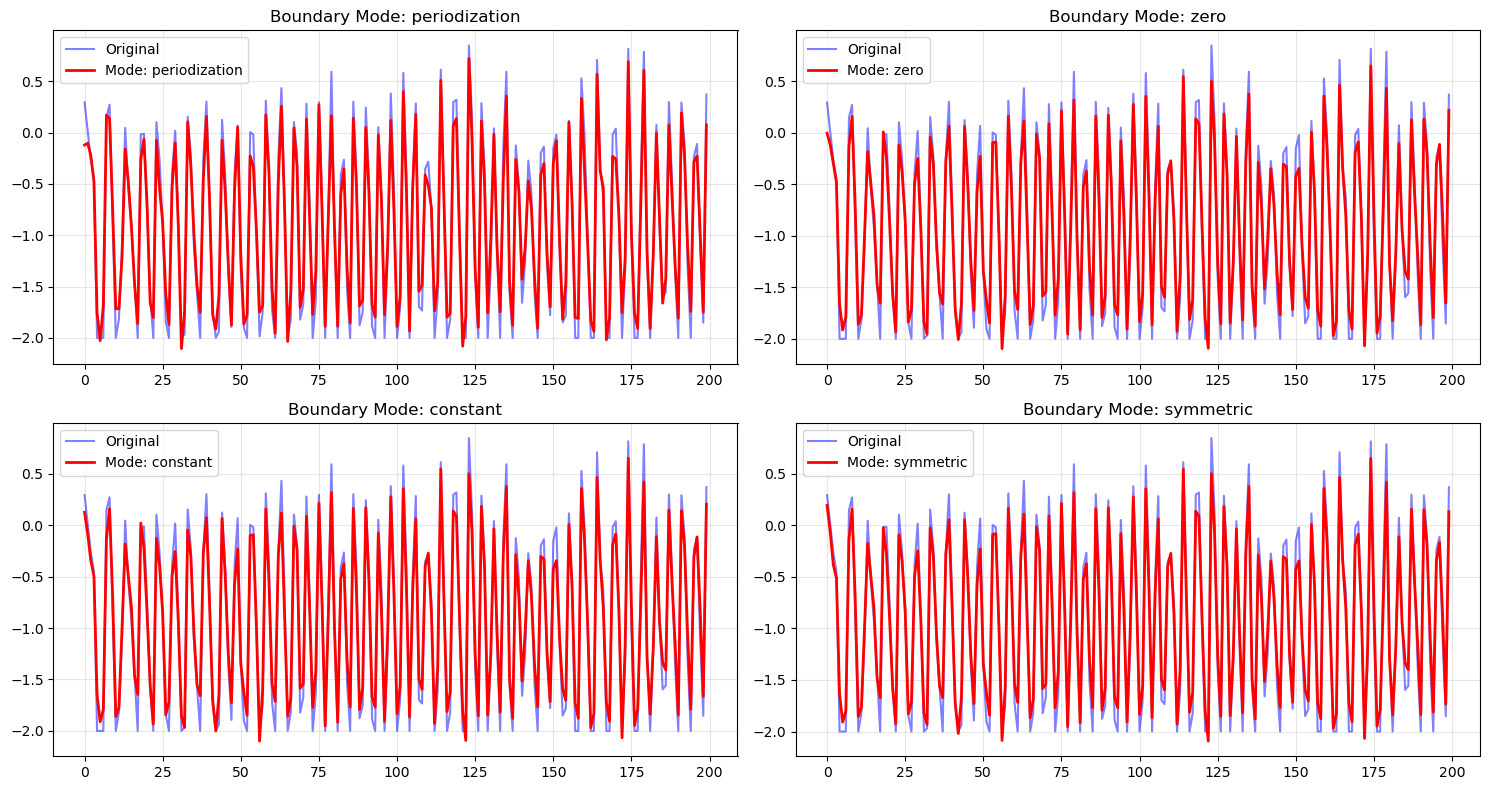

In [ ]:
def handle_boundary_effects(signal, wavelet='db6', mode='periodization'):
    """
    Demonstrate different approaches to handling boundary effects
    """
    modes = ['periodization', 'zero', 'constant', 'symmetric']
    
    results = {}
    for mode in modes:
        try:
            coeffs = pywt.wavedec(signal, wavelet, level=4, mode=mode)
            # Simple soft thresholding
            threshold = np.std(signal) * 0.2
            coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
            denoised = pywt.waverec(coeffs_thresh, wavelet, mode=mode)
            
            # Trim to original length if necessary
            if len(denoised) > len(signal):
                denoised = denoised[:len(signal)]
            
            results[mode] = denoised
        except Exception as e:
            results[mode] = f"Error: {str(e)}"
    
    return results

# Test boundary handling
boundary_results = handle_boundary_effects(signal[:200])  # Use shorter signal to see effects

plt.figure(figsize=(15, 8))
for i, (mode, result) in enumerate(boundary_results.items()):
    if isinstance(result, str):
        continue
        
    plt.subplot(2, 2, i+1)
    plt.plot(signal[:200], 'b-', alpha=0.5, label='Original')
    plt.plot(result, 'r-', linewidth=2, label=f'Mode: {mode}')
    plt.title(f'Boundary Mode: {mode}')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/boundary_effects_handling.png", dpi=300)
plt.show()